In [17]:
from src.config import  ANALYTICAL_DATA_PATH
from src.styles import NHS_COLORS

import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv(ANALYTICAL_DATA_PATH / 'combined.csv', parse_dates=['period'])

df.head()

,Region Code,Provider Code,Provider Name,Treatment Function Code,Treatment Function,>0-1,>1-2,>2-3,>3-4,>4-5,...,Total number of incomplete pathways,Total within 18 weeks,% within 18 weeks,Average (median) waiting time (in weeks),92nd percentile waiting time (in weeks),Total 52 plus weeks,Total 78 plus weeks,Total 65 plus weeks,% 52 plus weeks,period
0,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,94,177,129,133,155,...,4527,2443,0.539651,15.802239,37.207273,14,0,0,0.003093,2026-04-01
1,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,168,176,132,181,224,...,4114,2420,0.588235,15.151515,37.470526,37,0,0,NaN,2025-02-01
2,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,48,203,193,98,111,...,3867,2201,0.569175,16.040541,37.841000,10,0,0,0.002586,2025-03-01
3,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,106,172,128,165,191,...,3817,2296,0.601520,14.141892,37.504242,49,0,6,NaN,2024-03-01
4,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,156,155,144,204,140,...,3800,2331,0.613421,14.491071,37.370370,56,1,13,NaN,2024-02-01


In [22]:
df.info(verbose=True, show_counts=True)

selected_cols = [
    'Region Code',
    'Provider Code',
    'Provider Name',
    'Treatment Function Code',
    'Treatment Function',
    'Total number of incomplete pathways',
    'Total within 18 weeks',
    'Total 52 plus weeks',
    'Total 65 plus weeks',
    'Total 78 plus weeks',
    'Average (median) waiting time (in weeks)',
    '92nd percentile waiting time (in weeks)',
    'period'
    
]

df_eda = df[selected_cols].copy()
# sort the values chronologically by date
df_eda = df_eda.sort_values(by='period').reset_index(drop=True)

<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 120 columns):
 #    Column                                    Non-Null Count  Dtype         
---   ------                                    --------------  -----         
 0    Region Code                               31 non-null     str           
 1    Provider Code                             31 non-null     str           
 2    Provider Name                             31 non-null     str           
 3    Treatment Function Code                   31 non-null     str           
 4    Treatment Function                        31 non-null     str           
 5    >0-1                                      31 non-null     int64         
 6    >1-2                                      31 non-null     int64         
 7    >2-3                                      31 non-null     int64         
 8    >3-4                                      31 non-null     int64         
 9    >4-5                            

In [23]:
df_eda.columns.to_list()

['Region Code',
 'Provider Code',
 'Provider Name',
 'Treatment Function Code',
 'Treatment Function',
 'Total number of incomplete pathways',
 'Total within 18 weeks',
 'Total 52 plus weeks',
 'Total 65 plus weeks',
 'Total 78 plus weeks',
 'Average (median) waiting time (in weeks)',
 '92nd percentile waiting time (in weeks)',
 'period']

In [11]:
df_eda.info()

<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 13 columns):
 #   Column                                    Non-Null Count  Dtype         
---  ------                                    --------------  -----         
 0   Region Code                               31 non-null     str           
 1   Provider Code                             31 non-null     str           
 2   Provider Name                             31 non-null     str           
 3   Treatment Function Code                   31 non-null     str           
 4   Treatment Function                        31 non-null     str           
 5   Total number of incomplete pathways       31 non-null     int64         
 6   Total within 18 weeks                     31 non-null     int64         
 7   Total 52 plus weeks                       31 non-null     int64         
 8   Total 65 plus weeks                       31 non-null     int64         
 9   Total 78 plus weeks                       31 

In [12]:
df_eda.head()

,Region Code,Provider Code,Provider Name,Treatment Function Code,Treatment Function,Total number of incomplete pathways,Total within 18 weeks,Total 52 plus weeks,Total 65 plus weeks,Total 78 plus weeks,Average (median) waiting time (in weeks),92nd percentile waiting time (in weeks),period
0,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,4527,2443,14,0,0,15.802239,37.207273,2026-04-01
1,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,4114,2420,37,0,0,15.151515,37.470526,2025-02-01
2,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,3867,2201,10,0,0,16.040541,37.841000,2025-03-01
3,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,3817,2296,49,6,0,14.141892,37.504242,2024-03-01
4,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,3800,2331,56,13,1,14.491071,37.370370,2024-02-01


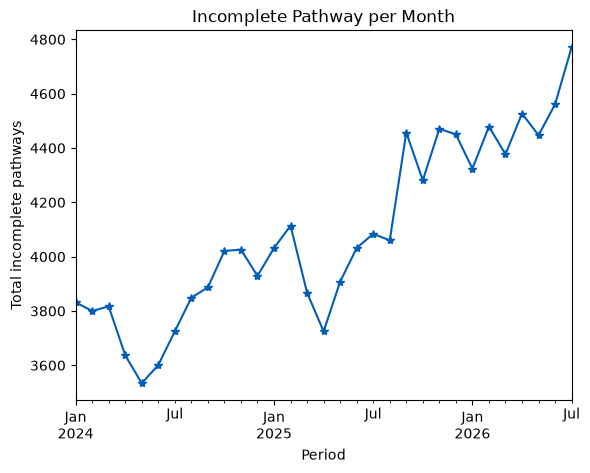

In [32]:
# plot the total incomplete pathways
df_eda.plot(y='Total number of incomplete pathways', x='period', color=NHS_COLORS['blue'], legend=False, marker='*')
plt.ylabel('Total incomplete pathways')
plt.xlabel('Period')
plt.title('Incomplete Pathway per Month')
plt.show()